In [1]:
!pip install -q torch scikit-learn pandas numpy matplotlib

import copy
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu128 | CUDA available: True


In [2]:
from google.colab import files

uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]
print("Using file:", CSV_PATH)

Saving Xiatang.csv to Xiatang.csv
Using file: Xiatang.csv


In [3]:
FEATURE_COLS = ["TEMP", "pH", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN", "DO"]  # COMMn = CODMn
TARGET_COL   = "DO"

LOOKBACK   = 24
HORIZON    = 6
TARGET_IDX = -1  # DO is the last column in FEATURE_COLS

BATCH_SIZE   = 32
HIDDEN_SIZE  = 128
NUM_LAYERS   = 2
DROPOUT      = 0.2
LR           = 1e-3
EPOCHS       = 100
PATIENCE     = 10
SEED         = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

np.random.seed(SEED)
torch.manual_seed(SEED)

Device: cuda


In [4]:
def load_and_clean(csv_path, max_interp_steps=12):
    df = pd.read_csv(csv_path)
    df["time"] = pd.to_datetime(df["time"])
    df = df.sort_values("time").drop_duplicates(subset="time")
    df = df.set_index("time")[FEATURE_COLS]

    full_index = pd.date_range(df.index.min(), df.index.max(), freq="4h")
    df = df.reindex(full_index)
    df.index.name = "time"

    df = df.interpolate(method="linear", limit=max_interp_steps, limit_direction="both")
    df = df.ffill().bfill()
    return df

df = load_and_clean(CSV_PATH)
print("Clean shape:", df.shape)
print("Remaining NaNs:\n", df.isna().sum())
df.head()

Clean shape: (10884, 9)
Remaining NaNs:
 TEMP     0
pH       0
EC       0
EUR      0
COMMn    0
NH3-N    0
TP       0
TN       0
DO       0
dtype: int64


,TEMP,pH,EC,EUR,COMMn,NH3-N,TP,TN,DO
time,,,,,,,,,
2020-12-17 20:00:00,1.600000,7.890000,385.25,23.250000,1.950000,0.03,0.0,1.280000,13.000000
2020-12-18 00:00:00,1.616667,7.888333,384.93,26.541667,2.001667,0.03,0.0,1.283333,13.001667
2020-12-18 04:00:00,1.633333,7.886667,384.61,29.833333,2.053333,0.03,0.0,1.286667,13.003333
2020-12-18 08:00:00,1.650000,7.885000,384.29,33.125000,2.105000,0.03,0.0,1.290000,13.005000
2020-12-18 12:00:00,1.666667,7.883333,383.97,36.416667,2.156667,0.03,0.0,1.293333,13.006667


In [5]:
def chronological_split(df, train_frac=0.7, val_frac=0.15):
    n = len(df)
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)
    train = df.iloc[:n_train]
    val = df.iloc[n_train:n_train + n_val]
    test = df.iloc[n_train + n_val:]
    return train, val, test

train_df, val_df, test_df = chronological_split(df)
print("train/val/test sizes:", len(train_df), len(val_df), len(test_df))

scaler = StandardScaler()
scaler.fit(train_df[FEATURE_COLS].values)

def scale_df(d):
    return scaler.transform(d[FEATURE_COLS].values)

train/val/test sizes: 7618 1632 1634


In [6]:
def make_windows(scaled_array, lookback=LOOKBACK, horizon=HORIZON, target_idx=TARGET_IDX):
    T = scaled_array.shape[0]
    n_samples = T - lookback - horizon + 1
    if n_samples <= 0:
        raise ValueError("Not enough timesteps for the requested lookback/horizon.")

    n_features = scaled_array.shape[1]
    X = np.zeros((n_samples, lookback, n_features), dtype=np.float32)
    y = np.zeros((n_samples, horizon), dtype=np.float32)

    for i in range(n_samples):
        X[i] = scaled_array[i:i + lookback]
        y[i] = scaled_array[i + lookback:i + lookback + horizon, target_idx]

    return X, y


class DOWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


X_train, y_train = make_windows(scale_df(train_df))
X_val,   y_val   = make_windows(scale_df(val_df))
X_test,  y_test  = make_windows(scale_df(test_df))

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

train_loader = DataLoader(DOWindowDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(DOWindowDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(DOWindowDataset(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

X_train: (7589, 24, 9) y_train: (7589, 6)
X_val:   (1603, 24, 9) y_val:   (1603, 6)
X_test:  (1605, 24, 9) y_test:  (1605, 6)


In [7]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                 dropout=DROPOUT, horizon=HORIZON):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, horizon),
        )

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = out[:, -1, :]
        return self.head(last_hidden)


model = LSTMForecaster(n_features=len(FEATURE_COLS)).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("Trainable params:", n_params)

LSTMForecaster(
  (lstm): LSTM(9, 128, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=128, out_features=6, bias=True)
  )
)
Trainable params: 204038


In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, n_batches = 0.0, 0
    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            loss = criterion(pred, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

    return total_loss / n_batches


criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    val_loss = run_epoch(model, val_loader, criterion, None)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch:3d}/{EPOCHS} | train_loss={train_loss:.5f} | val_loss={val_loss:.5f}")

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch} (patience={PATIENCE}).")
            break

model.load_state_dict(best_state)
torch.save(best_state, "best_model.pt")
print("Best val loss:", best_val_loss)


Epoch   1/100 | train_loss=0.13810 | val_loss=0.02979
Epoch   2/100 | train_loss=0.05774 | val_loss=0.02874
Epoch   3/100 | train_loss=0.05178 | val_loss=0.02705
Epoch   4/100 | train_loss=0.04958 | val_loss=0.02809
Epoch   5/100 | train_loss=0.04851 | val_loss=0.02481
Epoch   6/100 | train_loss=0.04668 | val_loss=0.02916
Epoch   7/100 | train_loss=0.04613 | val_loss=0.02755
Epoch   8/100 | train_loss=0.04528 | val_loss=0.02867
Epoch   9/100 | train_loss=0.04495 | val_loss=0.02871
Epoch  10/100 | train_loss=0.04423 | val_loss=0.03045
Epoch  11/100 | train_loss=0.04234 | val_loss=0.06077
Epoch  12/100 | train_loss=0.04314 | val_loss=0.03818
Epoch  13/100 | train_loss=0.04191 | val_loss=0.03975
Epoch  14/100 | train_loss=0.04123 | val_loss=0.05255
Epoch  15/100 | train_loss=0.04221 | val_loss=0.04707
Early stopping triggered at epoch 15 (patience=10).
Best val loss: 0.02481153123445955


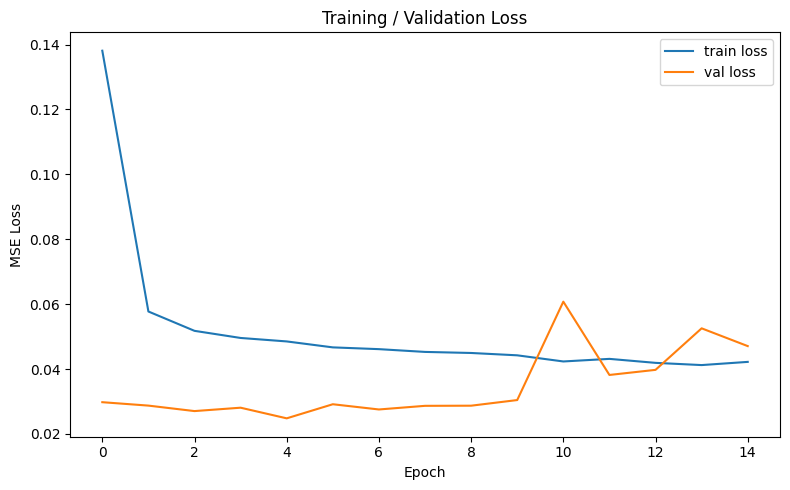

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("training_curve.png", dpi=150)
plt.show()

In [10]:
def inverse_transform_do(scaled_do):
    mean = scaler.mean_[-1]
    std = scaler.scale_[-1]
    return scaled_do * std + mean


def evaluate(model, loader):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            pred = model(xb).cpu().numpy()
            preds.append(pred)
            actuals.append(yb.numpy())
    preds = np.concatenate(preds, axis=0)
    actuals = np.concatenate(actuals, axis=0)

    preds_orig = inverse_transform_do(preds)
    actuals_orig = inverse_transform_do(actuals)

    metrics = {}
    for h in range(preds_orig.shape[1]):
        rmse = float(np.sqrt(mean_squared_error(actuals_orig[:, h], preds_orig[:, h])))
        mae = float(mean_absolute_error(actuals_orig[:, h], preds_orig[:, h]))
        r2 = float(r2_score(actuals_orig[:, h], preds_orig[:, h]))
        metrics[f"step_{h+1}"] = {"rmse": rmse, "mae": mae, "r2": r2}

    rmse_all = float(np.sqrt(mean_squared_error(actuals_orig.ravel(), preds_orig.ravel())))
    mae_all = float(mean_absolute_error(actuals_orig.ravel(), preds_orig.ravel()))
    r2_all = float(r2_score(actuals_orig.ravel(), preds_orig.ravel()))
    metrics["overall"] = {"rmse": rmse_all, "mae": mae_all, "r2": r2_all}
    return metrics, preds_orig, actuals_orig


metrics, preds_orig, actuals_orig = evaluate(model, test_loader)
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "step_1": {
    "rmse": 0.45685883841071595,
    "mae": 0.2776504571477253,
    "r2": 0.887584049341391
  },
  "step_2": {
    "rmse": 0.5340553375466234,
    "mae": 0.33920689347510086,
    "r2": 0.845981869219488
  },
  "step_3": {
    "rmse": 0.5871433572912694,
    "mae": 0.3729133826179515,
    "r2": 0.8133814256999852
  },
  "step_4": {
    "rmse": 0.6326413441389444,
    "mae": 0.4087257349478693,
    "r2": 0.7828358387880348
  },
  "step_5": {
    "rmse": 0.6828978222841052,
    "mae": 0.44672411160010267,
    "r2": 0.7464175021434019
  },
  "step_6": {
    "rmse": 0.7276682180960574,
    "mae": 0.4782383512986159,
    "r2": 0.7114592856279924
  },
  "overall": {
    "rmse": 0.6102947328174976,
    "mae": 0.3872431551812276,
    "r2": 0.7981787538127132
  }
}


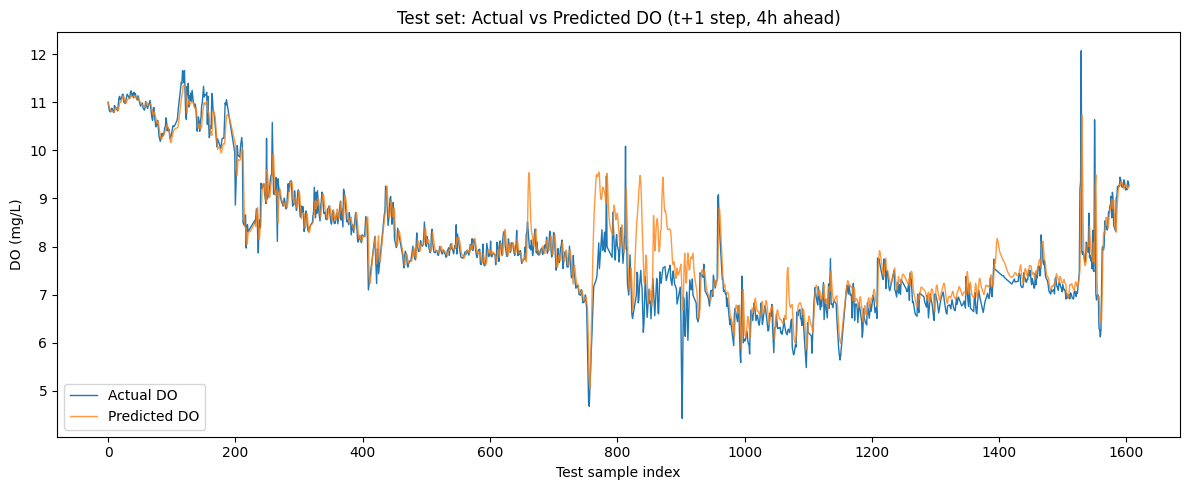

In [11]:
STEP_TO_PLOT = 0  # 0 = t+1 (4h ahead) ... 5 = t+6 (24h ahead)

plt.figure(figsize=(12, 5))
plt.plot(actuals_orig[:, STEP_TO_PLOT], label="Actual DO", linewidth=1)
plt.plot(preds_orig[:, STEP_TO_PLOT], label="Predicted DO", linewidth=1, alpha=0.8)
plt.xlabel("Test sample index")
plt.ylabel("DO (mg/L)")
plt.title(f"Test set: Actual vs Predicted DO (t+{STEP_TO_PLOT+1} step, {(STEP_TO_PLOT+1)*4}h ahead)")
plt.legend()
plt.tight_layout()
plt.savefig("test_predictions.png", dpi=150)
plt.show()